# 7. Principal component analysis and regression on components

A spectrum of many channels from a mixture of three species has three degrees of freedom, apart from noise. Principal component analysis finds them from the singular value decomposition of the data. The lecture checks the identities that the decomposition satisfies, uses the leading components as regressors, and shows the weakness of that regression: the components are chosen without looking at the quantity to be predicted.

## Learning objectives

1. Compute principal components from the singular value decomposition of the centred data (`dim_reduction.pca_svd`).
2. Check the orthonormality of the loadings, the orthogonality of the scores and the sum of the variances.
3. Check that the residual of a truncated model equals the sum of the discarded eigenvalues.
4. Regress on the leading components (`dim_reduction.pcr_regression`) and find the case in which this fails: a quantity carried by a component of small variance.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given a column-centered spectral or sensor matrix $\mathbf{X}_c = \mathbf{X} - \mathbf{1}_N\boldsymbol{\mu}^\top \in \mathbb{R}^{N \times d}$ with thin singular value decomposition $\mathbf{X}_c = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$ ($\boldsymbol{\Sigma} = \mathrm{diag}(\sigma_1, \dots, \sigma_r)$), the sample covariance matrix is $\mathbf{S}_{XX} = \frac{1}{N-1}\mathbf{X}_c^\top\mathbf{X}_c = \mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^\top$ with eigenvalues $\lambda_a = \sigma_a^2 / (N - 1)$. Retaining the top $k$ right singular vectors as the loading matrix $\mathbf{P}_k = [\mathbf{v}_1, \dots, \mathbf{v}_k] \in \mathbb{R}^{d \times k}$ gives the latent score matrix $\mathbf{T}_k$:
$$\mathbf{T}_k = \mathbf{X}_c\mathbf{P}_k = \mathbf{U}_k\boldsymbol{\Sigma}_k \in \mathbb{R}^{N \times k}, \qquad \mathbf{P}_k^\top\mathbf{P}_k = \mathbf{I}_k, \qquad \mathbf{T}_k^\top\mathbf{T}_k = (N - 1)\boldsymbol{\Lambda}_k \tag{1.1}$$
By the **Eckart–Young–Mirsky theorem**, $\hat{\mathbf{X}}_c^{(k)} = \mathbf{T}_k\mathbf{P}_k^\top$ is the optimal rank-$k$ approximation to $\mathbf{X}_c$ in Frobenius norm, and the total squared prediction error ($Q_{\mathrm{SPE}}$) equals the sum of the discarded eigenvalues:
$$\sum_{i=1}^N Q_{\mathrm{SPE},i} = \|\mathbf{X}_c - \mathbf{T}_k\mathbf{P}_k^\top\|_F^2 = \sum_{a=k+1}^{\min(N,d)} \sigma_a^2 = (N - 1)\sum_{a=k+1}^{\min(N,d)} \lambda_a \tag{1.2}$$
**Principal component regression (PCR)** regresses the centered target $\mathbf{y}_c = \mathbf{y} - \bar{y}\mathbf{1}_N$ onto $\mathbf{T}_k$:
$$\hat{\boldsymbol{\gamma}} = (\mathbf{T}_k^\top\mathbf{T}_k)^{-1}\mathbf{T}_k^\top\mathbf{y}_c, \qquad \hat{\boldsymbol{\beta}}_{\mathrm{PCR}} = \mathbf{P}_k\hat{\boldsymbol{\gamma}} = \sum_{a=1}^k \frac{\mathbf{u}_a^\top\mathbf{y}_c}{\sigma_a}\mathbf{v}_a \tag{1.3}$$

In [2]:
heading("Demonstration 1: SVD Principal Component Analysis & Orthogonality Identities")
rng = np.random.default_rng(42)
N, d = 45, 25
# 3 true underlying chemical species driving 25 spectral wavelengths:
C_latent = rng.normal(0.0, 1.0, size=(N, 3))
S_spectra = rng.normal(0.0, 1.0, size=(3, d))
X_spec = C_latent @ S_spectra + rng.normal(0.0, 0.05, size=(N, d))

pca3 = dim_reduction.pca_svd(X_spec, n_components=3)
pca_all = dim_reduction.pca_svd(X_spec, n_components=25)

assert np.allclose(pca3["loadings"].T @ pca3["loadings"], np.eye(3), atol=1e-13)
assert np.allclose(pca3["scores"].T @ pca3["scores"], (N - 1) * np.diag(pca3["eigenvalues"]), rtol=1e-12)
assert np.isclose(np.sum(pca_all["explained_variance_ratio"]), 1.0, rtol=1e-14)
print("Top 5 eigenvalues lambda_a:", np.round(pca_all["eigenvalues"][:5], 4))
print("Top-3 PCA cumulative variance explained:", f"{100.0 * np.sum(pca3['explained_variance_ratio']):.2f}%")
assert np.sum(pca3["explained_variance_ratio"]) > 0.99


Demonstration 1: SVD Principal Component Analysis & Orthogonality Identities
Top 5 eigenvalues lambda_a: [2.49651e+01 1.53015e+01 9.71700e+00 7.70000e-03 5.40000e-03]
Top-3 PCA cumulative variance explained: 99.89%


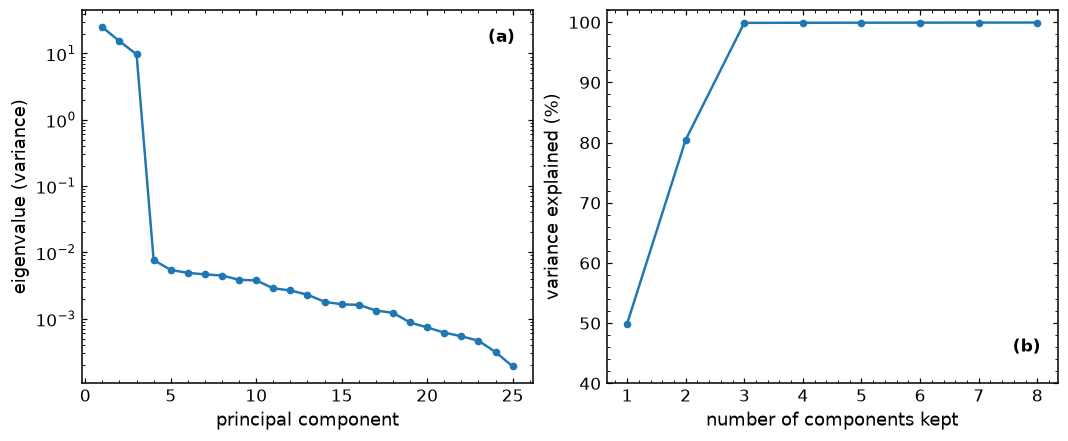

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
s_all = np.linalg.svd(X_spec - np.mean(X_spec, axis=0), compute_uv=False)
eig_all = s_all**2 / (N - 1)
ax1.semilogy(np.arange(1, len(eig_all) + 1), eig_all, "o-", ms=4)
ax1.set_xlabel("principal component"); ax1.set_ylabel("eigenvalue (variance)"); panel_label(ax1, "(a)", x=0.9)
ax2.plot(np.arange(1, 9), 100.0 * np.cumsum(eig_all)[:8] / np.sum(eig_all), "o-", ms=4)
ax2.set_xlabel("number of components kept"); ax2.set_ylabel("variance explained (%)"); ax2.set_ylim(40.0, 102.0); panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure 7.1.** Principal components of synthetic spectra of 25 channels generated by three species. (a) The eigenvalues of the covariance matrix: three stand three orders of magnitude above the rest, which are noise. (b) The share of the variance explained by the first components.

**What Demonstration 1 shows.** Three species generated the spectra of 25 channels, and the first three principal components carry $99.89\ \%$ of the variance. The eigenvalues fall from $9.7$ (third) to $0.008$ (fourth): the remaining 22 components are noise.

---

## 2. Numerical walkthrough
Let us verify the **Eckart–Young–Mirsky residual theorem** Eq. (1.2) across rank truncations $k \in \{1, 2, 3, 4, 5\}$: the sum of sample $Q_{\mathrm{SPE}}$ residuals identically equals $(N - 1)\sum_{a=k+1}^d \lambda_a$.

In [4]:
heading("Demonstration 2: Eckart-Young-Mirsky Rank-k Residual Identity Verification")
print(f"{'Rank k':>6s} | {'Cumul Var [%]':>13s} | {'sum(Q_SPE)':>14s} | {'(N-1)*sum(lam_>k)':>18s} | {'Discrepancy':>12s}")
print("-" * 74)
for k_rank in [1, 2, 3, 4, 5]:
    p_k = dim_reduction.pca_svd(X_spec, n_components=k_rank)
    q_sum = float(np.sum(p_k["q_spe"]))
    lam_tail = (N - 1) * float(np.sum(pca_all["eigenvalues"][k_rank:]))
    disc = abs(q_sum - lam_tail)
    print(f"{k_rank:6d} | {100*np.sum(p_k['explained_variance_ratio']):13.3f} | {q_sum:14.6f} | {lam_tail:18.6f} | {disc:12.2e}")
    assert np.isclose(q_sum, lam_tail, rtol=1e-11)


Demonstration 2: Eckart-Young-Mirsky Rank-k Residual Identity Verification
Rank k | Cumul Var [%] |     sum(Q_SPE) |  (N-1)*sum(lam_>k) |  Discrepancy
--------------------------------------------------------------------------
     1 |        49.893 |    1103.185801 |        1103.185801 |     4.55e-13
     2 |        80.473 |     429.919405 |         429.919405 |     1.14e-13
     3 |        99.892 |       2.371446 |           2.371446 |     8.88e-16
     4 |        99.908 |       2.034558 |           2.034558 |     0.00e+00
     5 |        99.918 |       1.796129 |           1.796129 |     8.88e-16


**What Demonstration 2 shows.** The residual sum of squares after keeping $k$ components equals $(N-1)$ times the sum of the discarded eigenvalues, to rounding error. It falls from $430$ at $k = 2$ to $2.4$ at $k = 3$ and hardly changes after that, which identifies three as the number of independent species.

---

## 3. Worked case study
Let us calibrate a 3-component **principal component regression (PCR)** model (`dim_reduction.pcr_regression`) predicting a bulk analyte concentration $\mathbf{y}_{\mathrm{target}}$ driven by the 3 major species, and compare its coefficient norm and out-of-sample stability against unregularized 25-wavelength OLS.

In [5]:
heading("Demonstration 3: 3-Component PCR vs. Full 25-Wavelength OLS Benchmark")
y_target = C_latent @ np.array([2.0, -1.5, 0.8]) + 4.0 + rng.normal(0.0, 0.04, size=N)
pcr3 = dim_reduction.pcr_regression(X_spec, y_target, n_components=3)
pcr_ols = dim_reduction.pcr_regression(X_spec, y_target, n_components=25)

C_test_lat = rng.normal(0.0, 1.0, size=(50, 3))
X_spec_test = C_test_lat @ S_spectra + rng.normal(0.0, 0.05, size=(50, d))
y_test_true = C_test_lat @ np.array([2.0, -1.5, 0.8]) + 4.0

pred_pcr3 = X_spec_test @ pcr3["coef"] + pcr3["intercept"]
pred_ols25 = X_spec_test @ pcr_ols["coef"] + pcr_ols["intercept"]
print(f"Coefficient L2 norm ||beta||_2: 3-PC PCR = {np.linalg.norm(pcr3['coef']):.4f} vs 25-Channel OLS = {np.linalg.norm(pcr_ols['coef']):.4f}")
print(f"Out-of-sample Test RMSE       : 3-PC PCR = {np.sqrt(np.mean((pred_pcr3 - y_test_true)**2)):.4f} vs 25-Channel OLS = {np.sqrt(np.mean((pred_ols25 - y_test_true)**2)):.4f}")
assert np.linalg.norm(pcr3["coef"]) < 0.70 * np.linalg.norm(pcr_ols["coef"])
assert np.sqrt(np.mean((pred_pcr3 - y_test_true) ** 2)) < np.sqrt(np.mean((pred_ols25 - y_test_true) ** 2))


Demonstration 3: 3-Component PCR vs. Full 25-Wavelength OLS Benchmark
Coefficient L2 norm ||beta||_2: 3-PC PCR = 0.4987 vs 25-Channel OLS = 1.3306
Out-of-sample Test RMSE       : 3-PC PCR = 0.0394 vs 25-Channel OLS = 0.0854


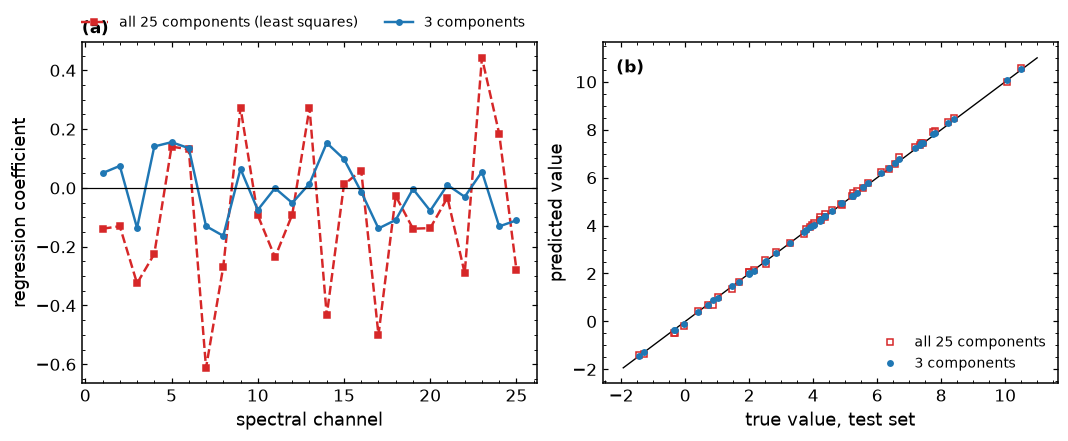

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(np.arange(1, d + 1), pcr_ols["coef"], "s--", ms=3.5, color="C3", label="all 25 components (least squares)")
ax1.plot(np.arange(1, d + 1), pcr3["coef"], "o-", ms=3.5, color="C0", label="3 components")
ax1.axhline(0.0, color="k", lw=0.8)
ax1.set_xlabel("spectral channel"); ax1.set_ylabel("regression coefficient"); ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax1.set_title("(a)", loc="left", fontweight="bold")
lims = [float(np.min(y_test_true)) - 0.5, float(np.max(y_test_true)) + 0.5]
ax2.plot(lims, lims, "k-", lw=0.9)
ax2.plot(y_test_true, pred_ols25, "s", ms=4, mfc="none", color="C3", label="all 25 components")
ax2.plot(y_test_true, pred_pcr3, "o", ms=3.5, color="C0", label="3 components")
ax2.set_xlabel("true value, test set"); ax2.set_ylabel("predicted value"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 7.2.** Regression on three principal components and on all 25. (a) The regression coefficients: with all components they are larger and irregular, because directions that carry only noise are divided by small singular values. (b) Predictions for 50 new samples.

**What Demonstration 3 shows.** Discarding the 22 noise components avoids the division by small singular values in Eq. (1.3). The norm of the regression vector falls from $1.33$ to $0.50$, and the error on data not used for the fit from $0.085$ to $0.039$.

---

## 4. What if: sensitivity to the parameters
What is the fundamental weakness of PCR? Suppose a high-toxicity **trace catalyst poison** $y_{\mathrm{trace}}$ absorbs along the 4th orthogonal singular vector $\mathbf{v}_4$ (which accounts for $<0.5\%$ of total spectral variance). What happens when we run 3-component PCR versus 1-component supervised PLS1?

In [7]:
heading("Demonstration 4: The Unsupervised PCR Failure Mode on Low-Variance Trace Analytes")
U_full, _, Vt_full = np.linalg.svd(X_spec - np.mean(X_spec, axis=0), full_matrices=False)
u4 = U_full[:, 3]
v4 = Vt_full[3, :]
X_with_trace = (X_spec - np.mean(X_spec, axis=0)) + np.outer(0.5 * u4, v4)
y_trace = X_with_trace @ v4

pcr_miss = dim_reduction.pcr_regression(X_with_trace, y_trace, n_components=3)
pls_hit = dim_reduction.pls1_nipals(X_with_trace, y_trace, n_components=1)
rmse_pcr_trace = float(np.sqrt(np.mean((pcr_miss["y_pred"] - y_trace) ** 2)))
rmse_pls_trace = float(np.sqrt(np.mean((pls_hit["y_pred"] - y_trace) ** 2)))
print(f"Trace Analyte RMSE: 3-Component Unsupervised PCR = {rmse_pcr_trace:.4f} (Blinded by variance truncation)")
print(f"Trace Analyte RMSE: 1-Component Supervised PLS1  = {rmse_pls_trace:.4e} (Finds trace direction immediately)")
assert rmse_pls_trace < 0.01 * rmse_pcr_trace


Demonstration 4: The Unsupervised PCR Failure Mode on Low-Variance Trace Analytes
Trace Analyte RMSE: 3-Component Unsupervised PCR = 0.1611 (Blinded by variance truncation)
Trace Analyte RMSE: 1-Component Supervised PLS1  = 5.6757e-13 (Finds trace direction immediately)


**What Demonstration 4 shows.** Principal components are ranked by the variance of the spectra and know nothing of $\mathbf{y}$. Here the analyte of interest lies along a direction of small variance, which the three-component regression discards; its error, $0.16$, is that of predicting the mean. PLS chooses its directions by their covariance with $\mathbf{y}$ and finds this one with a single component. Its error is at rounding level only because this synthetic analyte is an exact linear function of the spectra, with no noise.

---

## Inside the algorithm
Below we compute thin SVD PCA and PCR directly via `np.linalg.svd` in pure NumPy and verify digit-for-digit agreement with `dim_reduction.pca_svd` and `dim_reduction.pcr_regression`.

In [8]:
heading("Inside the Algorithm: By-Hand SVD PCA & PCR vs. the Library")
mu_x = np.mean(X_spec, axis=0)
Xc = X_spec - mu_x
U_s, S_s, Vt_s = np.linalg.svd(Xc, full_matrices=False)
P_hand = Vt_s[:3, :].T
T_hand = Xc @ P_hand
yc = y_target - float(np.mean(y_target))
gamma_hand = np.linalg.lstsq(T_hand, yc, rcond=None)[0]
beta_pcr_hand = P_hand @ gamma_hand
diff_pcr = float(np.max(np.abs(beta_pcr_hand - pcr3["coef"])))
print("by hand (pure NumPy) beta[:5]:", np.round(beta_pcr_hand[:5], 6))
print("library (engml_2_applied)      beta[:5]:", np.round(pcr3["coef"][:5], 6))
print(f"Max discrepancy              : {diff_pcr:.2e}")
assert diff_pcr < 1e-14


Inside the Algorithm: By-Hand SVD PCA & PCR vs. the Library
by hand (pure NumPy) beta[:5]: [ 0.050321  0.074862 -0.136296  0.140912  0.1555  ]
library (engml_2_applied)      beta[:5]: [ 0.050321  0.074862 -0.136296  0.140912  0.1555  ]
Max discrepancy              : 0.00e+00


## Exercises

1. **Verify a result.** Verify that when `n_components = d` ($k = 25$), `pcr_regression(X_spec, y_target, n_components=25)` recovers the exact ordinary least squares coefficient vector $\hat{\boldsymbol{\beta}}_{\mathrm{OLS}}$ and intercept to within $10^{-11}$.
2. **Find how it fails.** Demonstrate the **unit-scaling distortion** of unstandardized PCA: take a 3-sensor reactor table `[T_Kelvin, P_MPa, x_mole_fraction]` where $T \sim 450 \pm 25\;\mathrm{K}$, $P \sim 2.5 \pm 0.4\;\mathrm{MPa}$, and $x \sim 0.30 \pm 0.05$. Show that unscaled PCA assigns $>99.9\%$ of PC1's loading to the temperature because Kelvin has the largest numerical spread, whereas `descriptors.StandardScaler` restores balanced dimensionless loadings.
3. **Write it yourself.** Implement a function `pca_press_choose_k(X: np.ndarray, y: np.ndarray, k_max: int = 8) -> dict` that selects the optimal PCR component count $k^*$ using 5-fold cross-validation predicted residual error sum of Squares (PRESS), and verify on `(X_spec, y_target)` that it selects $k^* = 3$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Exact Equivalence of Full-Rank PCR (k = d) and OLS")
pcr_full = dim_reduction.pcr_regression(X_spec, y_target, n_components=d)
X_aug = np.column_stack([np.ones(N), X_spec])
w_ols_full = np.linalg.lstsq(X_aug, y_target, rcond=None)[0]
assert np.allclose(pcr_full["coef"], w_ols_full[1:], atol=1e-11)
assert np.isclose(pcr_full["intercept"], w_ols_full[0], atol=1e-11)
print("Max coefficient difference ||beta_PCR(k=d) - beta_OLS||_max:", float(np.max(np.abs(pcr_full["coef"] - w_ols_full[1:]))))


Exercise 1: Exact Equivalence of Full-Rank PCR (k = d) and OLS
Max coefficient difference ||beta_PCR(k=d) - beta_OLS||_max: 4.3576253716537394e-15
